In [1]:

import numpy as np
import matplotlib.pyplot as plt
import time
import heapq

print("Libraries imported successfully!")


Libraries imported successfully!


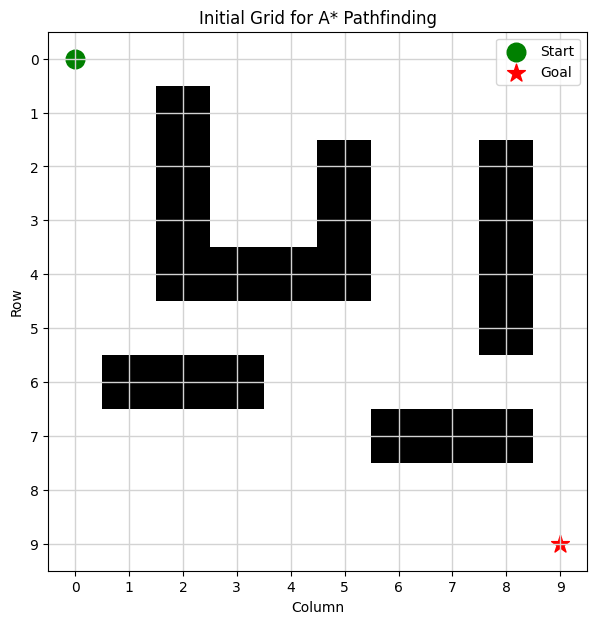

Grid size: (10, 10)
Start position: (0, 0)
Goal position: (9, 9)
Number of obstacles: 19


In [2]:

# Create a 10 x 10 grid
# 0 = free cell, 1 = obstacle

grid = np.zeros((10, 10), dtype=int)

# Add obstacles
obstacles = [
    (1, 2), (2, 2), (3, 2), (4, 2),
    (4, 3), (4, 4), (4, 5),
    (2, 5), (3, 5),
    (6, 1), (6, 2), (6, 3),
    (7, 6), (7, 7), (7, 8),
    (2, 8), (3, 8), (4, 8), (5, 8)
]

for row, col in obstacles:
    grid[row, col] = 1

# Define start and goal
start = (0, 0)
goal = (9, 9)

# Visualize the grid
plt.figure(figsize=(7, 7))
plt.imshow(grid, cmap="Greys", origin="upper", vmin=0, vmax=1)

# Display grid lines
plt.xticks(range(10))
plt.yticks(range(10))
plt.grid(True, color="lightgray", linewidth=1)

# Mark start and destination
plt.scatter(start[1], start[0], color="green",
            s=180, marker="o", label="Start")

plt.scatter(goal[1], goal[0], color="red",
            s=180, marker="*", label="Goal")

plt.title("Initial Grid for A* Pathfinding")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.show()

print("Grid size:", grid.shape)
print("Start position:", start)
print("Goal position:", goal)
print("Number of obstacles:", len(obstacles))


In [3]:

# A* Search Algorithm from Scratch

def heuristic(node, goal):
    """
    Manhattan Distance heuristic.
    Estimates the distance between the current node and the goal.
    """
    return abs(node[0] - goal[0]) + abs(node[1] - goal[1])


def get_neighbors(node, grid):
    """
    Returns valid neighboring cells.
    Movement is allowed in four directions only.
    """
    rows, cols = grid.shape
    row, col = node

    directions = [
        (-1, 0),  # Up
        (1, 0),   # Down
        (0, -1),  # Left
        (0, 1)    # Right
    ]

    neighbors = []

    for dr, dc in directions:
        new_row = row + dr
        new_col = col + dc

        if (
            0 <= new_row < rows
            and 0 <= new_col < cols
            and grid[new_row, new_col] == 0
        ):
            neighbors.append((new_row, new_col))

    return neighbors


def reconstruct_path(came_from, current):
    """Reconstructs the final path from goal to start."""
    path = [current]

    while current in came_from:
        current = came_from[current]
        path.append(current)

    path.reverse()
    return path


def astar_search(grid, start, goal):
    """
    Finds the shortest path using A* Search.

    Returns:
        path, expanded_nodes, execution_time
    """
    start_time = time.perf_counter()

    # Priority queue entries: (f_score, tie_breaker, node)
    open_list = []
    counter = 0

    heapq.heappush(
        open_list,
        (heuristic(start, goal), counter, start)
    )

    came_from = {}
    g_score = {start: 0}
    closed_set = set()
    expanded_nodes = 0

    while open_list:
        _, _, current = heapq.heappop(open_list)

        # Ignore outdated or already processed queue entries
        if current in closed_set:
            continue

        if current == goal:
            execution_time = time.perf_counter() - start_time
            path = reconstruct_path(came_from, current)

            return path, expanded_nodes, execution_time

        closed_set.add(current)
        expanded_nodes += 1

        for neighbor in get_neighbors(current, grid):
            if neighbor in closed_set:
                continue

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)
                counter += 1

                heapq.heappush(
                    open_list,
                    (f_score, counter, neighbor)
                )

    execution_time = time.perf_counter() - start_time
    return None, expanded_nodes, execution_time


# Run A* on our grid
path, expanded_nodes, execution_time = astar_search(
    grid, start, goal
)

# Display the results
if path is not None:
    path_steps = len(path) - 1

    print("A* Search Results")
    print("-" * 35)
    print("Path found:", True)
    print("Start:", start)
    print("Goal:", goal)
    print("Path length (steps):", path_steps)
    print("Path cells:", len(path))
    print("Expanded nodes:", expanded_nodes)
    print(f"Execution time: {execution_time:.6f} seconds")
    print("\nPath coordinates:")
    print(path)
else:
    print("No valid path exists between start and goal.")
    print("Expanded nodes:", expanded_nodes)
    print(f"Execution time: {execution_time:.6f} seconds")


A* Search Results
-----------------------------------
Path found: True
Start: (0, 0)
Goal: (9, 9)
Path length (steps): 18
Path cells: 19
Expanded nodes: 80
Execution time: 0.000309 seconds

Path coordinates:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]


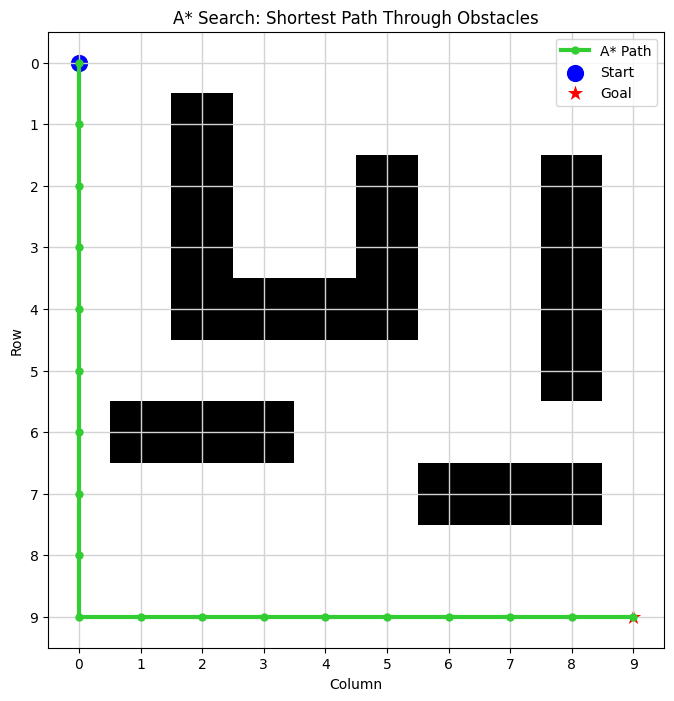

In [4]:

# Visualize the path found by A*

plt.figure(figsize=(8, 8))
plt.imshow(grid, cmap="Greys", origin="upper", vmin=0, vmax=1)

plt.xticks(range(grid.shape[1]))
plt.yticks(range(grid.shape[0]))
plt.grid(True, color="lightgray", linewidth=1)

# Plot the path
if path is not None:
    path_rows = [cell[0] for cell in path]
    path_cols = [cell[1] for cell in path]

    plt.plot(
        path_cols,
        path_rows,
        color="limegreen",
        linewidth=3,
        marker="o",
        markersize=5,
        label="A* Path"
    )

# Mark start and goal
plt.scatter(
    start[1], start[0],
    color="blue", s=180, marker="o",
    edgecolors="white", label="Start"
)

plt.scatter(
    goal[1], goal[0],
    color="red", s=220, marker="*",
    edgecolors="white", label="Goal"
)

plt.title("A* Search: Shortest Path Through Obstacles")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.show()


In [5]:

# Test A* on multiple grid configurations

def create_test_grid(size, obstacles):
    test_grid = np.zeros((size, size), dtype=int)

    for row, col in obstacles:
        test_grid[row, col] = 1

    return test_grid


test_cases = [
    {
        "name": "Test 1 - Original Grid",
        "grid": grid,
        "start": start,
        "goal": goal
    },
    {
        "name": "Test 2 - Open Grid",
        "grid": create_test_grid(10, []),
        "start": (0, 0),
        "goal": (9, 9)
    },
    {
        "name": "Test 3 - Moderate Obstacles",
        "grid": create_test_grid(
            10,
            [
                (1, 3), (2, 3), (3, 3), (4, 3),
                (5, 3), (5, 4), (5, 5),
                (2, 6), (3, 6), (4, 6),
                (7, 1), (7, 2), (7, 3)
            ]
        ),
        "start": (0, 0),
        "goal": (9, 9)
    },
    {
        "name": "Test 4 - Dense Obstacles",
        "grid": create_test_grid(
            10,
            [
                (0, 2), (1, 2), (2, 2), (3, 2),
                (4, 2), (5, 2), (6, 2),
                (2, 4), (2, 5), (2, 6),
                (4, 4), (5, 4), (6, 4),
                (6, 5), (6, 6), (6, 7),
                (1, 7), (2, 7), (3, 7), (4, 7)
            ]
        ),
        "start": (0, 0),
        "goal": (9, 9)
    }
]


results = []

for case in test_cases:
    test_grid = case["grid"]
    test_start = case["start"]
    test_goal = case["goal"]

    path, expanded, runtime = astar_search(
        test_grid, test_start, test_goal
    )

    results.append({
        "Test Case": case["name"],
        "Grid Size": f"{test_grid.shape[0]}x{test_grid.shape[1]}",
        "Obstacles": int(np.sum(test_grid)),
        "Path Found": path is not None,
        "Path Length (Steps)": len(path) - 1 if path else None,
        "Expanded Nodes": expanded,
        "Runtime (seconds)": round(runtime, 6)
    })


import pandas as pd

results_df = pd.DataFrame(results)

print("A* Search Performance Evaluation")
display(results_df)


A* Search Performance Evaluation


,Test Case,Grid Size,Obstacles,Path Found,Path Length (Steps),Expanded Nodes,Runtime (seconds)
0,Test 1 - Original Grid,10x10,19,True,18,80,0.004610
1,Test 2 - Open Grid,10x10,0,True,18,99,0.000607
2,Test 3 - Moderate Obstacles,10x10,13,True,18,85,0.000490
3,Test 4 - Dense Obstacles,10x10,20,True,18,43,0.006353


In [6]:

# Dijkstra's Algorithm from Scratch

def dijkstra_search(grid, start, goal):
    start_time = time.perf_counter()

    open_list = []
    counter = 0
    heapq.heappush(open_list, (0, counter, start))

    came_from = {}
    g_score = {start: 0}
    closed_set = set()
    expanded_nodes = 0

    while open_list:
        current_cost, _, current = heapq.heappop(open_list)

        if current in closed_set:
            continue

        if current == goal:
            execution_time = time.perf_counter() - start_time
            path = reconstruct_path(came_from, current)
            return path, expanded_nodes, execution_time

        closed_set.add(current)
        expanded_nodes += 1

        for neighbor in get_neighbors(current, grid):
            if neighbor in closed_set:
                continue

            tentative_cost = current_cost + 1

            if tentative_cost < g_score.get(
                neighbor, float("inf")
            ):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_cost

                counter += 1
                heapq.heappush(
                    open_list,
                    (tentative_cost, counter, neighbor)
                )

    execution_time = time.perf_counter() - start_time
    return None, expanded_nodes, execution_time


# Compare A* and Dijkstra on the same test cases
comparison_results = []

for case in test_cases:
    test_grid = case["grid"]
    test_start = case["start"]
    test_goal = case["goal"]

    for algorithm_name, algorithm in [
        ("A*", astar_search),
        ("Dijkstra", dijkstra_search)
    ]:
        # Repeat runs to reduce the influence of timing noise
        runtimes = []
        path = None
        expanded = 0

        for _ in range(20):
            path, expanded, runtime = algorithm(
                test_grid, test_start, test_goal
            )
            runtimes.append(runtime)

        average_runtime = sum(runtimes) / len(runtimes)

        comparison_results.append({
            "Test Case": case["name"],
            "Algorithm": algorithm_name,
            "Path Found": path is not None,
            "Path Length (Steps)": (
                len(path) - 1 if path is not None else None
            ),
            "Expanded Nodes": expanded,
            "Average Runtime (seconds)": round(
                average_runtime, 6
            )
        })


comparison_df = pd.DataFrame(comparison_results)

print("A* vs Dijkstra Performance Comparison")
display(comparison_df)


A* vs Dijkstra Performance Comparison


,Test Case,Algorithm,Path Found,Path Length (Steps),Expanded Nodes,Average Runtime (seconds)
0,Test 1 - Original Grid,A*,True,18,80,0.000324
1,Test 1 - Original Grid,Dijkstra,True,18,80,0.000291
2,Test 2 - Open Grid,A*,True,18,99,0.000343
3,Test 2 - Open Grid,Dijkstra,True,18,99,0.000303
4,Test 3 - Moderate Obstacles,A*,True,18,85,0.000282
5,Test 3 - Moderate Obstacles,Dijkstra,True,18,86,0.000258
6,Test 4 - Dense Obstacles,A*,True,18,43,0.000147
7,Test 4 - Dense Obstacles,Dijkstra,True,18,58,0.000233


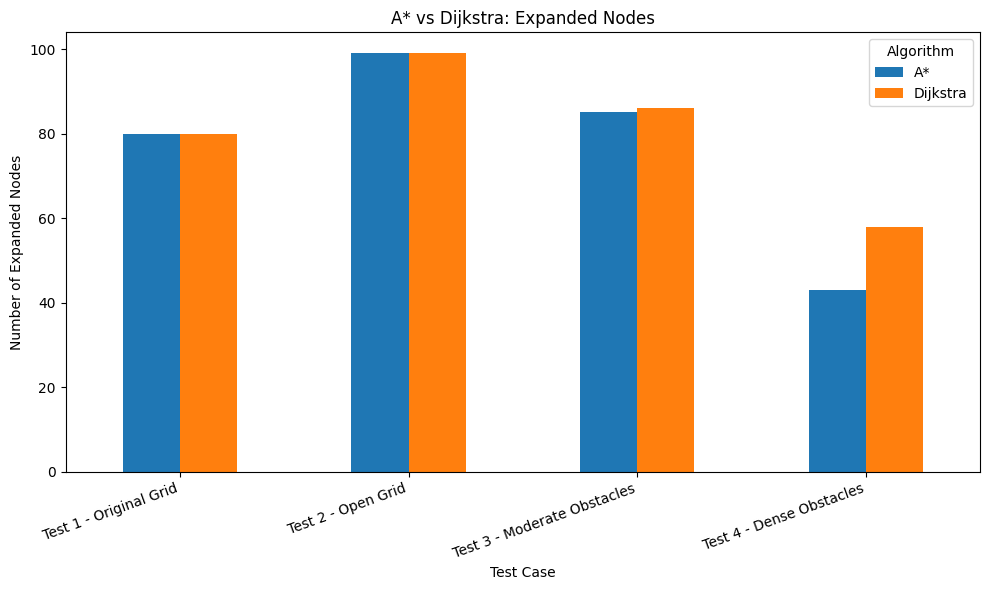

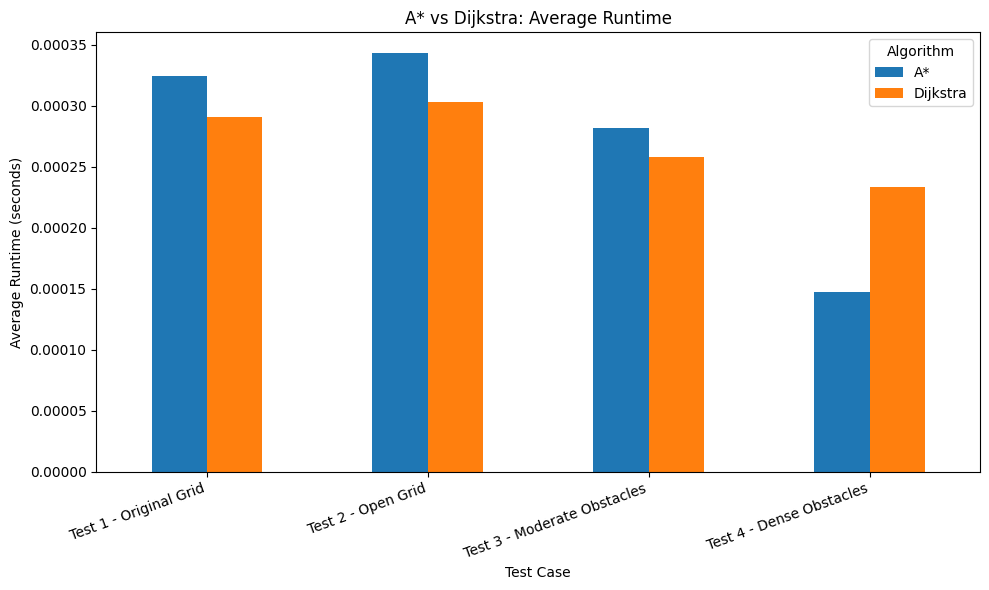

Both comparison charts generated and saved successfully.


In [7]:

# Visualize A* vs Dijkstra performance

# 1. Expanded nodes comparison
pivot_nodes = comparison_df.pivot(
    index="Test Case",
    columns="Algorithm",
    values="Expanded Nodes"
)

pivot_nodes.plot(kind="bar", figsize=(10, 6))

plt.title("A* vs Dijkstra: Expanded Nodes")
plt.xlabel("Test Case")
plt.ylabel("Number of Expanded Nodes")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Algorithm")
plt.tight_layout()
plt.savefig("astar_dijkstra_expanded_nodes.png", dpi=300)
plt.show()


# 2. Average runtime comparison
pivot_runtime = comparison_df.pivot(
    index="Test Case",
    columns="Algorithm",
    values="Average Runtime (seconds)"
)

pivot_runtime.plot(kind="bar", figsize=(10, 6))

plt.title("A* vs Dijkstra: Average Runtime")
plt.xlabel("Test Case")
plt.ylabel("Average Runtime (seconds)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Algorithm")
plt.tight_layout()
plt.savefig("astar_dijkstra_runtime.png", dpi=300)
plt.show()


print("Both comparison charts generated and saved successfully.")
